# Song2Vec: Music Recommendation with Word2Vec

**Overview.** Playlists are treated as sentences and tracks as words, so Word2Vec learns track embeddings from how often tracks appear together in user playlists. The embeddings drive next-track prediction, similar-song retrieval and a multi-seed recommender. Hyperparameters are tuned for recommendation rather than NLP, following Caselles-Dupré et al. (2018), [*Word2Vec applied to Recommendation: Hyperparameters Matter*](https://arxiv.org/abs/1804.04212).

**Dataset.** [30Music](https://remaplab.deib.polimi.it/resources/) (Turrin et al., 2015), playlists collected from Last.fm. `playlist.idomaar` and `tracks.idomaar` yield 47,130 playlists with at least two resolvable tracks, 1,601,748 track occurrences, 444,075 unique tracks and 60,184 artists. Playlists are split 80/20 into 37,704 train and 9,426 test playlists.

**Approach.**
- Gensim Word2Vec trained on playlists as sequences of `artist__title` tokens
- Baseline with NLP defaults, then one-at-a-time sweeps over `ns_exponent`, `window`, `epochs`, architecture (CBOW vs. skip-gram), `negative`, `min_count` and `vector_size`
- HR@K and NDCG@K (K = 5, 10, 20, 50) with two query strategies: the previous track (single query) and the average of all previous tracks (context average)
- Qualitative checks: nearest neighbours, song algebra and t-SNE
- Recommender built on averaged seed embeddings, plus cold-start and popularity analysis

**Key results.**
- Single-query HR@10 rose from 0.0145 (baseline) to 0.0930 (tuned), a +541.4% improvement
- Best tuned result with context averaging: HR@10 = 0.0965, NDCG@10 = 0.0584, HR@50 = 0.1795
- Tuned configuration: `ns_exponent=0`, `window=10`, `epochs=50`, skip-gram, `negative=15`, `min_count=10`, `vector_size=100`
- `epochs` and `min_count` had the largest effect; `ns_exponent` and `vector_size` had little

## Setup

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import gensim

import json
import re
import tqdm
from urllib.parse import unquote_plus
from collections import Counter, defaultdict
from sklearn import manifold as man
from sklearn import model_selection as mod

In [4]:
# 30Music files (see README for download instructions)
PLAYLIST_FILE = "data/playlist.idomaar"
TRACKS_FILE = "data/tracks.idomaar"

## 1. Data preparation and exploration

### Parsing track metadata

Each track's `name` field is URL-decoded and split on `/_/` into artist and title. Both parts are lowercased and whitespace-normalized, then joined into a single `artist__title` token.

In [7]:
track_map = {}

with open(TRACKS_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in tqdm.tqdm(f, desc="Parsing tracks"):
        try:
            parts = line.strip().split("\t")
            track_id = int(parts[1])
            metadata = json.loads(parts[3])
            raw_name = metadata.get("name", "")
            decoded = unquote_plus(raw_name)  # decode URL encoding

            if "/_/" in decoded:
                artist, title = decoded.split("/_/", 1)
            else:
                artist = "unknown"
                title = decoded

            artist = re.sub(r"\s+", " ", artist.lower().strip())
            title = re.sub(r"\s+", " ", title.lower().strip())
            track_map[track_id] = artist + "__" + title
        except:
            continue

print(f"Parsed {len(track_map)} tracks")

Parsed 4519105 tracks


In [8]:
for tid, name in list(track_map.items())[:5]:
    print(tid, "->", name)

0 -> 000003 music instructor__dj's rock da house â≈æ≈ê01 - dj max-pulemet vs. bomfunk mc's - electro breakdance party 1 [2000] = cd oneâ≈æ≈ê
1 -> 00-01__текст
2 -> 0005. overkill__overkill
3 -> 000c tony dize__ruleta rusa
4 -> 000 oscarcito__tumbay‚ (lyrics)


### Parsing playlists

Each playlist becomes a sequence of `artist__title` tokens. Playlists with fewer than two resolvable tracks are dropped.

In [9]:
playlists = []

with open(PLAYLIST_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in tqdm.tqdm(f, desc="Parsing playlists"):
        try:
            parts = line.strip().split("\t")
            subj_obj = json.loads(parts[4])

            track_names = []
            for obj in subj_obj.get("objects", []):
                if obj.get("type") == "track":
                    tid = int(obj["id"])
                    if tid in track_map:
                        track_names.append(track_map[tid])

            if len(track_names) >= 2:
                playlists.append(track_names)
        except:
            continue

print(f"Total playlists: {len(playlists)}")

Total playlists: 47130


In [15]:
playlists[0][:10]

['the whip__trash (crookers remix)',
 'modeselektor__sucker pin',
 'simian mobile disco__hustler',
 'gossip__standing in the way of control',
 'kalwi & remi__explosion (dj theo remix)',
 'jackson and his computer band__arpeggio',
 'midnight juggernauts__into the galaxy',
 "klaxons__it's not over yet",
 'yeah yeah yeahs__maps',
 'radiohead__true love waits (live)']

### Train / test split

80/20 split at the playlist level (`random_state=42`).

In [16]:
train_playlists, test_playlists = mod.train_test_split(
    playlists, test_size=0.2, random_state=42
)
print(f"Train: {len(train_playlists)}, Test: {len(test_playlists)}")

Train: 37704, Test: 9426


### Playlist length distribution

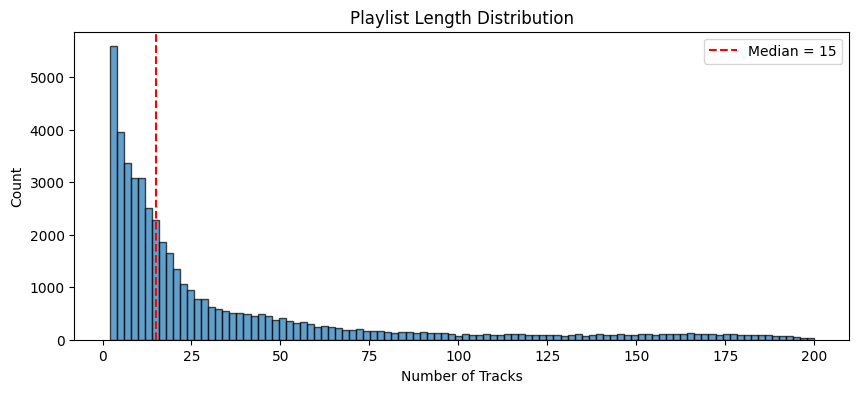

Mean: 34.0, Median: 15
Min: 2, Max: 200


In [17]:
playlist_lengths = [len(p) for p in playlists]

plt.figure(figsize=(10, 4))
plt.hist(playlist_lengths, bins=100, edgecolor="black", alpha=0.7)
plt.xlabel("Number of Tracks")
plt.ylabel("Count")
plt.title("Playlist Length Distribution")
plt.axvline(np.median(playlist_lengths), color="red", linestyle="--",
            label=f"Median = {np.median(playlist_lengths):.0f}")
plt.legend()
plt.show()

print(f"Mean: {np.mean(playlist_lengths):.1f}, Median: {np.median(playlist_lengths):.0f}")
print(f"Min: {min(playlist_lengths)}, Max: {max(playlist_lengths)}")

Playlist length is right-skewed: the mean (34.0) is more than twice the median (15), with a long tail of playlists up to 200 tracks. Short playlists offer limited context for both training and evaluation, while longer ones carry richer co-occurrence signal.

### Track frequency distribution (log-log)

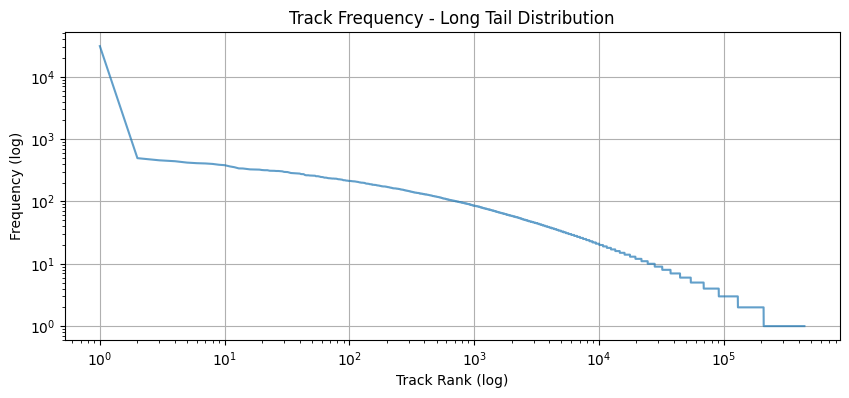

In [18]:
all_tracks = [t for pl in playlists for t in pl]
track_counts = Counter(all_tracks)
counts_sorted = sorted(track_counts.values(), reverse=True)

plt.figure(figsize=(10, 4))
plt.loglog(range(1, len(counts_sorted)+1), counts_sorted, alpha=0.7)
plt.xlabel("Track Rank (log)")
plt.ylabel("Frequency (log)")
plt.title("Track Frequency - Long Tail Distribution")
plt.grid(True)
plt.show()

Track popularity follows a power law with a very long tail of rarely played tracks.

### Top 20 tracks and artists

In [19]:
print("=== Top 20 Tracks ===")
for i, (track, count) in enumerate(track_counts.most_common(20), 1):
    print(f"  {i:2d}. {track}  ({count})")

artist_counts = Counter()
for track, count in track_counts.items():
    artist_counts[track.split("__")[0]] += count

print("\n=== Top 20 Artists ===")
for i, (artist, count) in enumerate(artist_counts.most_common(20), 1):
    print(f"  {i:2d}. {artist}  ({count})")

=== Top 20 Tracks ===
   1. zz top__she loves my automobile  (31036)
   2. massive attack__teardrop  (495)
   3. joy division__love will tear us apart  (457)
   4. radiohead__karma police  (442)
   5. nirvana__smells like teen spirit  (420)
   6. mgmt__kids  (411)
   7. radiohead__creep  (407)
   8. oasis__wonderwall  (400)
   9. the rolling stones__paint it black  (388)
  10. the killers__mr. brightside  (382)
  11. mgmt__time to pretend  (365)
  12. franz ferdinand__take me out  (354)
  13. muse__starlight  (339)
  14. depeche mode__enjoy the silence  (338)
  15. kings of leon__sex on fire  (332)
  16. coldplay__viva la vida  (327)
  17. led zeppelin__stairway to heaven  (326)
  18. radiohead__paranoid android  (325)
  19. system of a down__chop suey!  (324)
  20. johnny cash__hurt  (319)

=== Top 20 Artists ===
   1. zz top  (31713)
   2. radiohead  (7703)
   3. the beatles  (6541)
   4. coldplay  (4563)
   5. pink floyd  (4481)
   6. depeche mode  (4305)
   7. muse  (4298)
   8. me

`zz top__she loves my automobile` appears 31,036 times, over 60x the next track (`massive attack__teardrop`, 495). This is most likely a data artifact or bot activity, and it distorts the frequency distribution. Apart from that outlier, the most frequent artists are classic rock and alternative acts such as Radiohead (7,703), The Beatles (6,541), Coldplay (4,563), Pink Floyd (4,481) and Depeche Mode (4,305).

### Vocabulary statistics

In [20]:
total_unique = len(track_counts)
hapax = sum(1 for c in track_counts.values() if c == 1)
total_events = sum(track_counts.values())

print(f"Total events:       {total_events:,}")
print(f"Unique tracks:      {total_unique:,}")
print(f"Unique artists:     {len(artist_counts):,}")
print(f"Hapax (count=1):    {hapax:,} ({100*hapax/total_unique:.1f}%)")
print(f"Tracks count <= 5:  {sum(1 for c in track_counts.values() if c<=5):,}")

Total events:       1,601,748
Unique tracks:      444,075
Unique artists:     60,184
Hapax (count=1):    235,010 (52.9%)
Tracks count <= 5:  389,603


The vocabulary is extremely sparse: 235,010 of the 444,075 unique tracks (52.9%) appear only once, and 389,603 (87.7%) appear five times or fewer. A `min_count` of 5 therefore discards most of the catalogue.

## 2. Model training

### Baseline: NLP defaults

Skip-gram with `window=5`, `ns_exponent=0.75`, `negative=5`, `min_count=5`, `vector_size=100` and `epochs=5`.

In [21]:
baseline_model = gensim.models.Word2Vec(
    sentences=train_playlists,
    vector_size=100, window=5, min_count=5,
    sg=1, negative=5, ns_exponent=0.75,
    workers=4, epochs=5, seed=42
)
print(f"Vocab size: {len(baseline_model.wv)}")

Vocab size: 54623


### Hyperparameter sweeps

Each sweep varies one parameter while the others stay fixed at skip-gram, `window=5`, `ns_exponent=-0.5`, `negative=5`, `min_count=5`, `vector_size=100` and `epochs=10`. The first sweep covers `ns_exponent`, the exponent of the negative-sampling distribution, which Caselles-Dupré et al. (2018) identify as the most influential parameter for recommendation.

In [22]:
# ns_exponent
ns_models = {}
for val in [-1.0, -0.5, 0, 0.5, 1.0]:
    print(f"ns_exponent = {val}")
    ns_models[val] = gensim.models.Word2Vec(
        sentences=train_playlists,
        vector_size=100, window=5, min_count=5, sg=1,
        negative=5, ns_exponent=val, workers=4, epochs=10, seed=42
    )

ns_exponent = -1.0
ns_exponent = -0.5
ns_exponent = 0
ns_exponent = 0.5
ns_exponent = 1.0


In [23]:
# Window size
window_models = {}
for val in [3, 5, 7, 10]:
    print(f"window = {val}")
    window_models[val] = gensim.models.Word2Vec(
        sentences=train_playlists,
        vector_size=100, window=val, min_count=5, sg=1,
        negative=5, ns_exponent=-0.5, workers=4, epochs=10, seed=42
    )

window = 3
window = 5
window = 7
window = 10


In [24]:
# epochs
epoch_models = {}
for val in [5, 10, 20, 50]:
    print(f"epochs = {val}")
    epoch_models[val] = gensim.models.Word2Vec(
        sentences=train_playlists,
        vector_size=100, window=5, min_count=5, sg=1,
        negative=5, ns_exponent=-0.5, workers=4, epochs=val, seed=42
    )

epochs = 5
epochs = 10
epochs = 20
epochs = 50


In [25]:
# sg, negative, min_count, vector_size

sg_models = {}
for val in [0, 1]:
    print(f"sg = {val}")
    sg_models[val] = gensim.models.Word2Vec(
        sentences=train_playlists,
        vector_size=100, window=5, min_count=5, sg=val,
        negative=5, ns_exponent=-0.5, workers=4, epochs=10, seed=42
    )

neg_models = {}
for val in [5, 10, 15]:
    print(f"negative = {val}")
    neg_models[val] = gensim.models.Word2Vec(
        sentences=train_playlists,
        vector_size=100, window=5, min_count=5, sg=1,
        negative=val, ns_exponent=-0.5, workers=4, epochs=10, seed=42
    )

print("Done!")

mc_models = {}
for val in [3, 5, 10]:
    print(f"min_count = {val}")
    mc_models[val] = gensim.models.Word2Vec(
        sentences=train_playlists,
        vector_size=100, window=5, min_count=val, sg=1,
        negative=5, ns_exponent=-0.5, workers=4, epochs=10, seed=42
    )

vs_models = {}
for val in [50, 100, 200]:
    print(f"vector_size = {val}")
    vs_models[val] = gensim.models.Word2Vec(
        sentences=train_playlists,
        vector_size=val, window=5, min_count=5, sg=1,
        negative=5, ns_exponent=-0.5, workers=4, epochs=10, seed=42
    )

print("Done!")

sg = 0
sg = 1
negative = 5
negative = 10
negative = 15
Done!
min_count = 3
min_count = 5
min_count = 10
vector_size = 50
vector_size = 100
vector_size = 200
Done!


## 3. Evaluation

### Sweep metric: single-query HR@10

For each of the first 2,000 test playlists, out-of-vocabulary tracks are removed, the second-to-last remaining track is the query and the last one is the target. A hit is counted when the target is among the query's 10 nearest neighbours. This follows the evaluation protocol of Caselles-Dupré et al. (2018).

In [ ]:
# Using paper approach (single query song) for hyperparameter comparison

def eval_hr10(model, test_data, max_test=2000):
    vocab = set(model.wv.key_to_index.keys())
    hits = 0
    n = 0

    for pl in test_data[:max_test]:
        in_vocab = [s for s in pl if s in vocab]
        if len(in_vocab) < 2:
            continue
        query = in_vocab[-2]
        target = in_vocab[-1]

        similar = model.wv.most_similar(query, topn=11)
        preds = [s for s, _ in similar if s != query][:10]
        n += 1
        if target in preds:
            hits += 1

    return hits / n if n > 0 else 0

In [27]:
# Evaluate all sweeps

print("=== ns_exponent ===")
ns_scores = {}
for val, m in ns_models.items():
    ns_scores[val] = eval_hr10(m, test_playlists)
    print(f"  {val:5.1f} -> HR@10 = {ns_scores[val]:.4f}")
best_ns = max(ns_scores, key=ns_scores.get)
print(f"  Best: {best_ns}\n")

print("=== window ===")
win_scores = {}
for val, m in window_models.items():
    win_scores[val] = eval_hr10(m, test_playlists)
    print(f"  {val} -> HR@10 = {win_scores[val]:.4f}")
best_win = max(win_scores, key=win_scores.get)
print(f"  Best: {best_win}\n")

print("=== epochs ===")
ep_scores = {}
for val, m in epoch_models.items():
    ep_scores[val] = eval_hr10(m, test_playlists)
    print(f"  {val} -> HR@10 = {ep_scores[val]:.4f}")
best_ep = max(ep_scores, key=ep_scores.get)
print(f"  Best: {best_ep}\n")

print("=== sg ===")
sg_scores = {}
for val, m in sg_models.items():
    sg_scores[val] = eval_hr10(m, test_playlists)
    print(f"  {val} -> HR@10 = {sg_scores[val]:.4f}")
best_sg = max(sg_scores, key=sg_scores.get)
print(f"  Best: {best_sg}\n")

print("=== negative ===")
neg_scores = {}
for val, m in neg_models.items():
    neg_scores[val] = eval_hr10(m, test_playlists)
    print(f"  {val} -> HR@10 = {neg_scores[val]:.4f}")
best_neg = max(neg_scores, key=neg_scores.get)
print(f"  Best: {best_neg}\n")

print("=== min_count ===")
mc_scores = {}
for val, m in mc_models.items():
    mc_scores[val] = eval_hr10(m, test_playlists)
    print(f"  {val} -> HR@10 = {mc_scores[val]:.4f}")
best_mc = max(mc_scores, key=mc_scores.get)
print(f"  Best: {best_mc}\n")

print("=== vector_size ===")
vs_scores = {}
for val, m in vs_models.items():
    vs_scores[val] = eval_hr10(m, test_playlists)
    print(f"  {val} -> HR@10 = {vs_scores[val]:.4f}")
best_vs = max(vs_scores, key=vs_scores.get)
print(f"  Best: {best_vs}")

=== ns_exponent ===
   -1.0 -> HR@10 = 0.0259
   -0.5 -> HR@10 = 0.0253
    0.0 -> HR@10 = 0.0283
    0.5 -> HR@10 = 0.0277
    1.0 -> HR@10 = 0.0271
  Best: 0

=== window ===
  3 -> HR@10 = 0.0206
  5 -> HR@10 = 0.0283
  7 -> HR@10 = 0.0318
  10 -> HR@10 = 0.0324
  Best: 10

=== epochs ===
  5 -> HR@10 = 0.0077
  10 -> HR@10 = 0.0271
  20 -> HR@10 = 0.0400
  50 -> HR@10 = 0.0494
  Best: 50

=== sg ===
  0 -> HR@10 = 0.0088
  1 -> HR@10 = 0.0277
  Best: 1

=== negative ===
  5 -> HR@10 = 0.0283
  10 -> HR@10 = 0.0353
  15 -> HR@10 = 0.0377
  Best: 15

=== min_count ===
  3 -> HR@10 = 0.0146
  5 -> HR@10 = 0.0288
  10 -> HR@10 = 0.0537
  Best: 10

=== vector_size ===
  50 -> HR@10 = 0.0241
  100 -> HR@10 = 0.0253
  200 -> HR@10 = 0.0247
  Best: 100


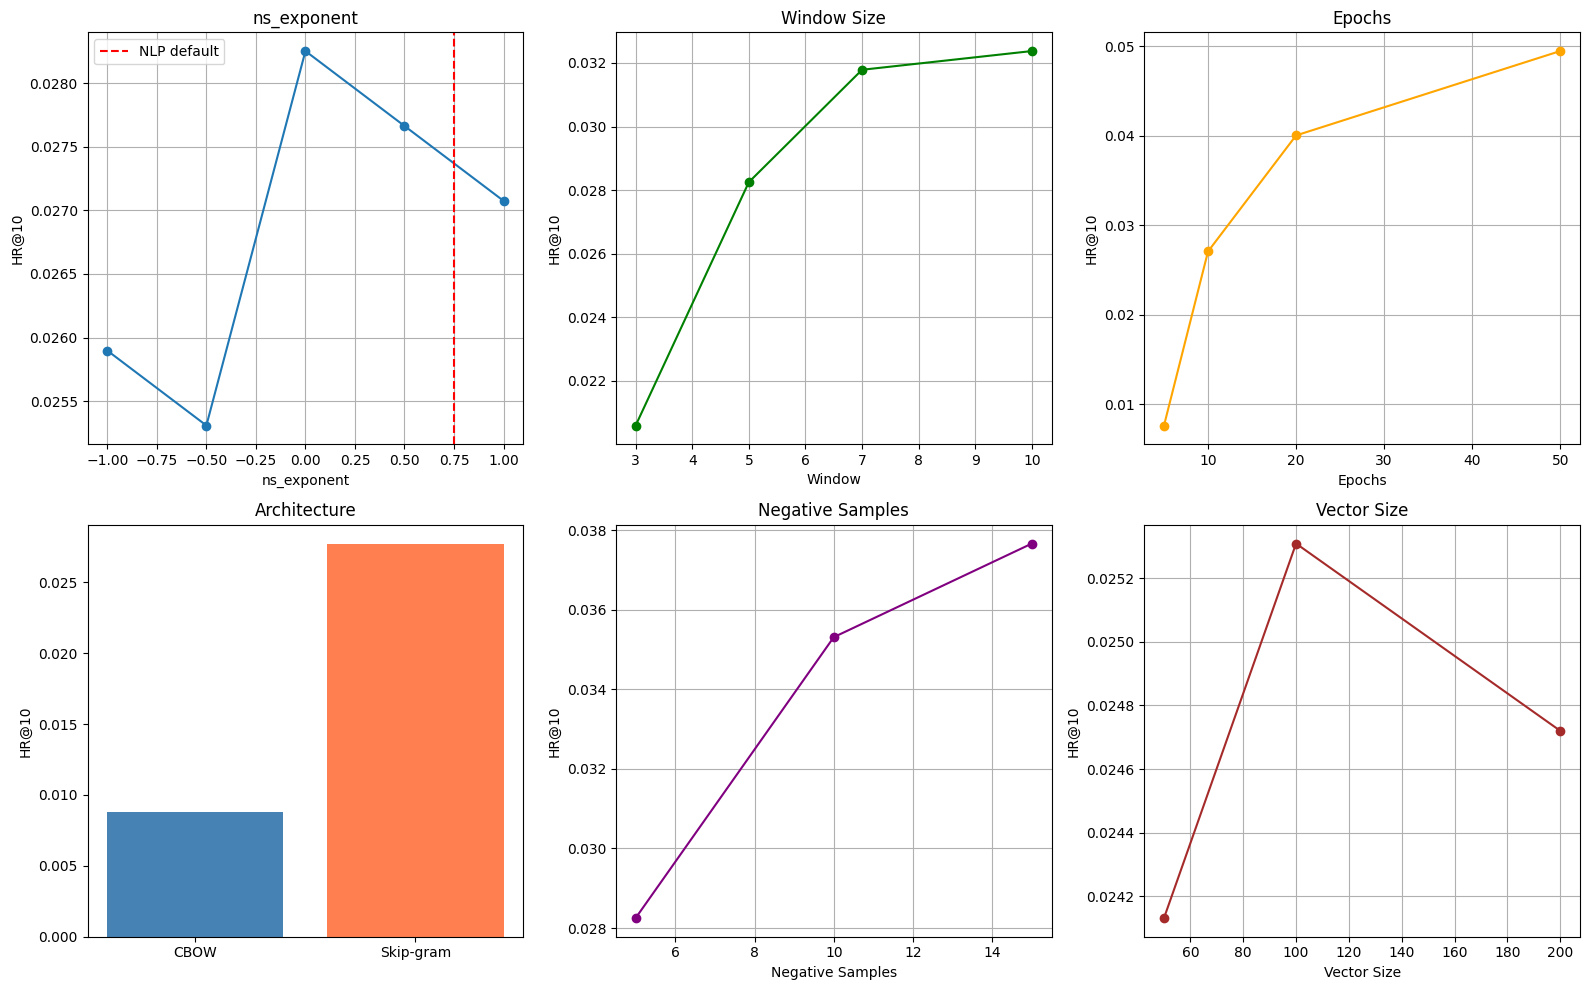

In [28]:
# Sensitivity plots

plt.figure(figsize=(16, 10))

plt.subplot(2, 3, 1)
plt.plot(sorted(ns_scores.keys()), [ns_scores[k] for k in sorted(ns_scores.keys())], "o-")
plt.axvline(0.75, color="red", linestyle="--", label="NLP default")
plt.xlabel("ns_exponent"); plt.ylabel("HR@10"); plt.title("ns_exponent"); plt.legend(); plt.grid(True)

plt.subplot(2, 3, 2)
plt.plot(sorted(win_scores.keys()), [win_scores[k] for k in sorted(win_scores.keys())], "o-", color="green")
plt.xlabel("Window"); plt.ylabel("HR@10"); plt.title("Window Size"); plt.grid(True)

plt.subplot(2, 3, 3)
plt.plot(sorted(ep_scores.keys()), [ep_scores[k] for k in sorted(ep_scores.keys())], "o-", color="orange")
plt.xlabel("Epochs"); plt.ylabel("HR@10"); plt.title("Epochs"); plt.grid(True)

plt.subplot(2, 3, 4)
plt.bar(["CBOW", "Skip-gram"], [sg_scores[0], sg_scores[1]], color=["steelblue", "coral"])
plt.ylabel("HR@10"); plt.title("Architecture")

plt.subplot(2, 3, 5)
plt.plot(sorted(neg_scores.keys()), [neg_scores[k] for k in sorted(neg_scores.keys())], "o-", color="purple")
plt.xlabel("Negative Samples"); plt.ylabel("HR@10"); plt.title("Negative Samples"); plt.grid(True)

plt.subplot(2, 3, 6)
plt.plot(sorted(vs_scores.keys()), [vs_scores[k] for k in sorted(vs_scores.keys())], "o-", color="brown")
plt.xlabel("Vector Size"); plt.ylabel("HR@10"); plt.title("Vector Size"); plt.grid(True)

plt.tight_layout()
plt.show()

**Sweep findings**
- **Epochs** had the largest effect: HR@10 rose from 0.0077 at 5 epochs to 0.0494 at 50. Recommendation corpora are much smaller than NLP corpora and need more passes, as the paper also reports.
- **min_count**: higher thresholds helped substantially (0.0146, 0.0288 and 0.0537 for 3, 5 and 10). Removing noisy rare tracks lets the model focus on tracks with enough data, at the cost of catalogue coverage.
- **Architecture**: skip-gram (0.0277) clearly beat CBOW (0.0088). Skip-gram handles rare items better, which matters on data this sparse.
- **Negative samples**: more negatives helped (0.0283, 0.0353 and 0.0377 for 5, 10 and 15).
- **Window**: larger windows were better, rising monotonically from 0.0206 (3) to 0.0324 (10). Playlists are not ordered like sentences, so tracks far apart can still be related.
- **ns_exponent**: 0 scored best (0.0283), but all values fell within about 0.003 of each other, and the negative values recommended by the paper (-0.5: 0.0253, -1.0: 0.0259) did not help here. The extreme ZZ Top outlier likely changes the negative-sampling dynamics, which makes uniform sampling (`ns_exponent=0`) the most balanced choice.
- **vector_size** was nearly flat (0.0241, 0.0253 and 0.0247 for 50, 100 and 200), suggesting the data does not support higher dimensions.

### Tuned model

The tuned model combines the best value from each sweep: `ns_exponent=0`, `window=10`, `epochs=50`, skip-gram, `negative=15`, `min_count=10` and `vector_size=100`.

In [29]:
# Train final optimized model

optimized_model = gensim.models.Word2Vec(
    sentences=train_playlists,
    vector_size=best_vs, window=best_win, min_count=best_mc,
    sg=best_sg, negative=best_neg, ns_exponent=best_ns,
    workers=4, epochs=best_ep, seed=42
)
print(f"Optimized vocab: {len(optimized_model.wv)}")

Optimized vocab: 21393


### Full evaluation: HR@K and NDCG@K

The baseline and tuned models are evaluated on 2,000 test playlists that contain at least two in-vocabulary tracks, for K = 5, 10, 20 and 50. The last track is the target, and two query strategies are compared:
- **Context average:** the mean embedding of all preceding tracks is the query.
- **Single query (paper):** the second-to-last track is the query.

In [ ]:
def full_evaluate(model, test_data, max_test=2000):
    vocab = set(model.wv.key_to_index.keys())
    k_values = [5, 10, 20, 50]

    # prepare usable test playlists
    usable = []
    for pl in test_data:
        inv = [s for s in pl if s in vocab]
        if len(inv) >= 2:
            usable.append(inv)
    usable = usable[:max_test]

    results = {}
    for approach in ["context_avg", "paper"]:
        hits = {k: 0 for k in k_values}
        ndcg = {k: 0.0 for k in k_values}
        count = 0

        for pl in usable:
            target = pl[-1]

            if approach == "context_avg":
                context = pl[:-1]
                avg_vec = np.mean([model.wv[s] for s in context], axis=0)
                sim = model.wv.similar_by_vector(avg_vec, topn=60)
                preds = [s for s, _ in sim if s not in set(context)][:50]
            else:
                query = pl[-2]
                sim = model.wv.most_similar(query, topn=51)
                preds = [s for s, _ in sim if s != query][:50]

            count += 1
            for k in k_values:
                if target in preds[:k]:
                    hits[k] += 1
                    rank = preds[:k].index(target) + 1
                    ndcg[k] += 1.0 / np.log2(rank + 1)

        results[approach] = {
            "HR": {k: hits[k]/count for k in k_values},
            "NDCG": {k: ndcg[k]/count for k in k_values},
            "n": count
        }
    return results

In [31]:
# evaluate baseline
print("=== BASELINE MODEL ===")
base_res = full_evaluate(baseline_model, test_playlists)

for app in ["context_avg", "paper"]:
    label = "Context Avg" if app == "context_avg" else "Paper (Single Query)"
    print(f"\n  {label} (n={base_res[app]['n']})")
    for k in [5, 10, 20, 50]:
        print(f"    K={k:2d}  HR={base_res[app]['HR'][k]:.4f}  NDCG={base_res[app]['NDCG'][k]:.4f}")

=== BASELINE MODEL ===

  Context Avg (n=2000)
    K= 5  HR=0.0090  NDCG=0.0064
    K=10  HR=0.0105  NDCG=0.0068
    K=20  HR=0.0180  NDCG=0.0087
    K=50  HR=0.0315  NDCG=0.0114

  Paper (Single Query) (n=2000)
    K= 5  HR=0.0110  NDCG=0.0071
    K=10  HR=0.0145  NDCG=0.0082
    K=20  HR=0.0245  NDCG=0.0107
    K=50  HR=0.0350  NDCG=0.0128


In [32]:
# evaluate optimized
print("=== OPTIMIZED MODEL ===")
opt_res = full_evaluate(optimized_model, test_playlists)

for app in ["context_avg", "paper"]:
    label = "Context Avg" if app == "context_avg" else "Paper (Single Query)"
    print(f"\n  {label} (n={opt_res[app]['n']})")
    for k in [5, 10, 20, 50]:
        print(f"    K={k:2d}  HR={opt_res[app]['HR'][k]:.4f}  NDCG={opt_res[app]['NDCG'][k]:.4f}")


=== OPTIMIZED MODEL ===

  Context Avg (n=2000)
    K= 5  HR=0.0700  NDCG=0.0498
    K=10  HR=0.0965  NDCG=0.0584
    K=20  HR=0.1325  NDCG=0.0674
    K=50  HR=0.1795  NDCG=0.0767

  Paper (Single Query) (n=2000)
    K= 5  HR=0.0685  NDCG=0.0453
    K=10  HR=0.0930  NDCG=0.0530
    K=20  HR=0.1240  NDCG=0.0609
    K=50  HR=0.1655  NDCG=0.0692


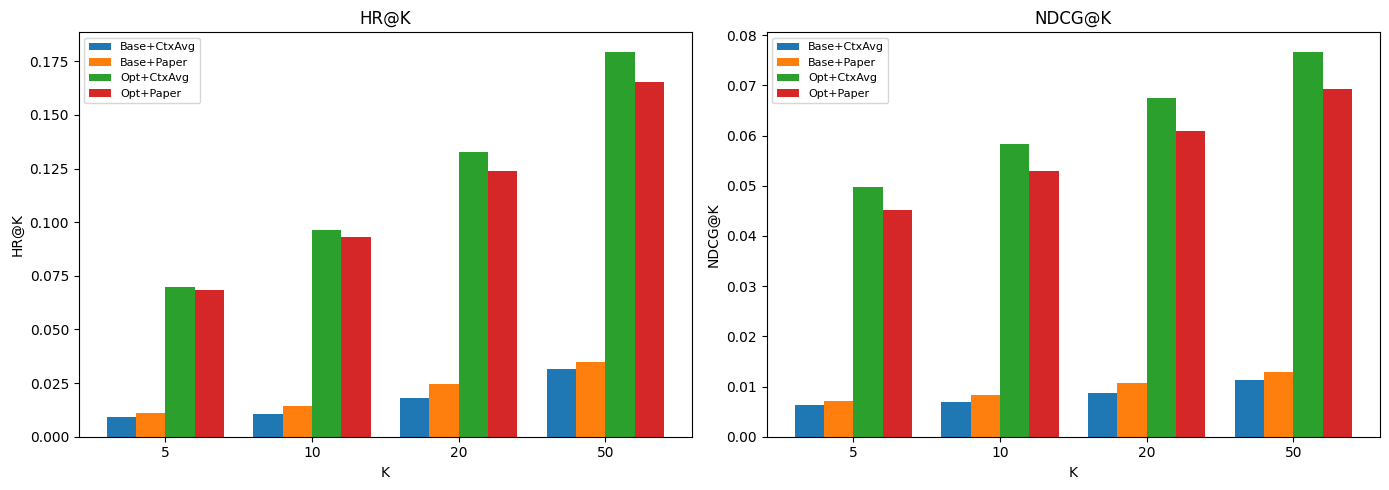

In [33]:
# comparison bar chart

k_values = [5, 10, 20, 50]
x = np.arange(len(k_values))
w = 0.2

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.bar(x-1.5*w, [base_res["context_avg"]["HR"][k] for k in k_values], w, label="Base+CtxAvg")
plt.bar(x-0.5*w, [base_res["paper"]["HR"][k] for k in k_values], w, label="Base+Paper")
plt.bar(x+0.5*w, [opt_res["context_avg"]["HR"][k] for k in k_values], w, label="Opt+CtxAvg")
plt.bar(x+1.5*w, [opt_res["paper"]["HR"][k] for k in k_values], w, label="Opt+Paper")
plt.xticks(x, [str(k) for k in k_values]); plt.xlabel("K"); plt.ylabel("HR@K")
plt.title("HR@K"); plt.legend(fontsize=8)

plt.subplot(1, 2, 2)
plt.bar(x-1.5*w, [base_res["context_avg"]["NDCG"][k] for k in k_values], w, label="Base+CtxAvg")
plt.bar(x-0.5*w, [base_res["paper"]["NDCG"][k] for k in k_values], w, label="Base+Paper")
plt.bar(x+0.5*w, [opt_res["context_avg"]["NDCG"][k] for k in k_values], w, label="Opt+CtxAvg")
plt.bar(x+1.5*w, [opt_res["paper"]["NDCG"][k] for k in k_values], w, label="Opt+Paper")
plt.xticks(x, [str(k) for k in k_values]); plt.xlabel("K"); plt.ylabel("NDCG@K")
plt.title("NDCG@K"); plt.legend(fontsize=8)

plt.tight_layout()
plt.show()

The tuned model improves single-query HR@10 from 0.0145 to 0.0930 (+541.4%), with large gains at every K and on NDCG.

The better query strategy depends on embedding quality. With the tuned model, context averaging slightly beats the single-query approach (HR@10 0.0965 vs. 0.0930), while with the baseline the single-query approach wins (0.0145 vs. 0.0105). With well-trained embeddings (50 epochs, `window=10`), averaging several tracks gives a more informative query; with weak embeddings, averaging many noisy vectors mainly adds noise.

### Nearest neighbours for seed tracks

In [34]:
vocab_list = list(optimized_model.wv.key_to_index.keys())

# try to find well-known seeds, fallback to popular tracks
seed_candidates = [
    "queen__bohemian rhapsody",
    "led zeppelin__stairway to heaven",
    "nirvana__smells like teen spirit",
    "michael jackson__billie jean",
    "radiohead__creep",
    "the beatles__let it be",
    "coldplay__the scientist",
]

seeds = []
for s in seed_candidates:
    if s in optimized_model.wv:
        seeds.append(s)
    else:
        # try partial match
        artist = s.split("__")[0]
        matches = [v for v in vocab_list if artist in v]
        if matches:
            seeds.append(matches[0])

# if not enough, add top frequent tracks
if len(seeds) < 5:
    for track, _ in track_counts.most_common(50):
        if track in optimized_model.wv and track not in seeds:
            seeds.append(track)
            if len(seeds) >= 7:
                break

print("=== Top-10 Similar Songs ===")
for seed in seeds:
    print(f"\nSeed: {seed}")
    for i, (track, score) in enumerate(optimized_model.wv.most_similar(seed, topn=10), 1):
        print(f"  {i:2d}. {track}  ({score:.4f})")

=== Top-10 Similar Songs ===

Seed: queen__bohemian rhapsody
   1. queen__we will rock you  (0.7845)
   2. queen__another one bites the dust  (0.7453)
   3. queen__don't stop me now  (0.6902)
   4. queen__killer queen  (0.6894)
   5. queen__i want to break free  (0.6832)
   6. queen__we are the champions  (0.6610)
   7. queen__somebody to love  (0.6598)
   8. queen__the show must go on  (0.6547)
   9. queen__bicycle race  (0.6503)
  10. queen__i want it all  (0.6411)

Seed: led zeppelin__stairway to heaven
   1. led zeppelin__whole lotta love  (0.6640)
   2. led zeppelin__black dog  (0.6458)
   3. led zeppelin__kashmir  (0.6389)
   4. led zeppelin__immigrant song  (0.6384)
   5. led zeppelin__rock and roll  (0.6278)
   6. led zeppelin__since i've been loving you  (0.6243)
   7. led zeppelin__babe i'm gonna leave you  (0.6203)
   8. pink floyd__wish you were here  (0.5918)
   9. pink floyd__comfortably numb  (0.5882)
  10. led zeppelin__communication breakdown  (0.5839)

Seed: nirvana__

Neighbour lists are dominated by the seed's own artist: all top-10 results for Queen, Nirvana, Michael Jackson and Radiohead are by the same artist. Some cross-artist structure still appears. `led zeppelin__stairway to heaven` retrieves two Pink Floyd tracks (`wish you were here`, 0.5918, and `comfortably numb`, 0.5882), as these bands often appear together in classic rock playlists.

### Song algebra

Vector arithmetic of the form `a - b + c`, where `a` and `b` are tracks by one artist and `c` is a track by another artist.

In [35]:
print("=== Song Algebra ===")

artist_to_tracks = defaultdict(list)
for t in vocab_list:
    artist_to_tracks[t.split("__")[0]].append(t)

# pick artists with enough songs
big_artists = [a for a, ts in artist_to_tracks.items() if len(ts) >= 5]
big_artists = big_artists[:6]

for i in range(min(4, len(big_artists)-1)):
    a1 = big_artists[i]
    a2 = big_artists[i+1]
    t1 = artist_to_tracks[a1][0]
    t2 = artist_to_tracks[a1][1]
    t3 = artist_to_tracks[a2][0]

    print(f"\n{t1} - {t2} + {t3} = ?")
    vec = optimized_model.wv[t1] - optimized_model.wv[t2] + optimized_model.wv[t3]
    for rank, (track, score) in enumerate(optimized_model.wv.most_similar(vec, topn=5), 1):
        print(f"  {rank}. {track}  ({score:.4f})")

=== Song Algebra ===

zz top__she loves my automobile - zz top__la grange + massive attack__teardrop = ?
  1. massive attack__teardrop  (0.6268)
  2. massive attack__angel  (0.4926)
  3. secret garden__song from a secret garden  (0.4820)
  4. massive attack__dissolved girl  (0.4765)
  5. sneaker pimps__walking zero  (0.4702)

massive attack__teardrop - massive attack__angel + joy division__love will tear us apart = ?
  1. joy division__love will tear us apart  (0.8250)
  2. joy division__she's lost control  (0.6630)
  3. joy division__transmission  (0.6400)
  4. new order__blue monday  (0.5991)
  5. joy division__disorder  (0.5930)

joy division__love will tear us apart - joy division__she's lost control + radiohead__karma police = ?
  1. radiohead__karma police  (0.8135)
  2. radiohead__fake plastic trees  (0.6776)
  3. radiohead__paranoid android  (0.6750)
  4. radiohead__creep  (0.6459)
  5. radiohead__no surprises  (0.6448)

radiohead__karma police - radiohead__creep + mgmt__kids =

Results are mixed. The arithmetic does move the query to the third artist (Joy Division − Joy Division + Radiohead returns Radiohead tracks, and Radiohead − Radiohead + MGMT returns MGMT tracks), but in every example the added track `c` itself is ranked first, so the subtraction does not cancel cleanly.

### t-SNE of song embeddings

Two-dimensional t-SNE projection of up to 25 tracks for each of the 12 artists with the most in-vocabulary tracks.

In [36]:
N_ARTISTS = 12
top_artists = [a for a, _ in Counter({a: len(ts) for a, ts in artist_to_tracks.items()
                                       if a in [t.split("__")[0] for t in vocab_list]}).most_common(N_ARTISTS)]

all_embs = []
all_labels = []

for artist in top_artists:
    tracks = [t for t in artist_to_tracks[artist] if t in optimized_model.wv][:25]
    for t in tracks:
        all_embs.append(optimized_model.wv[t])
        all_labels.append(artist)

all_embs = np.array(all_embs)
print(f"t-SNE on {len(all_embs)} tracks...")

tsne = man.TSNE(n_components=2, random_state=42, perplexity=30)
coords = tsne.fit_transform(all_embs)

t-SNE on 300 tracks...


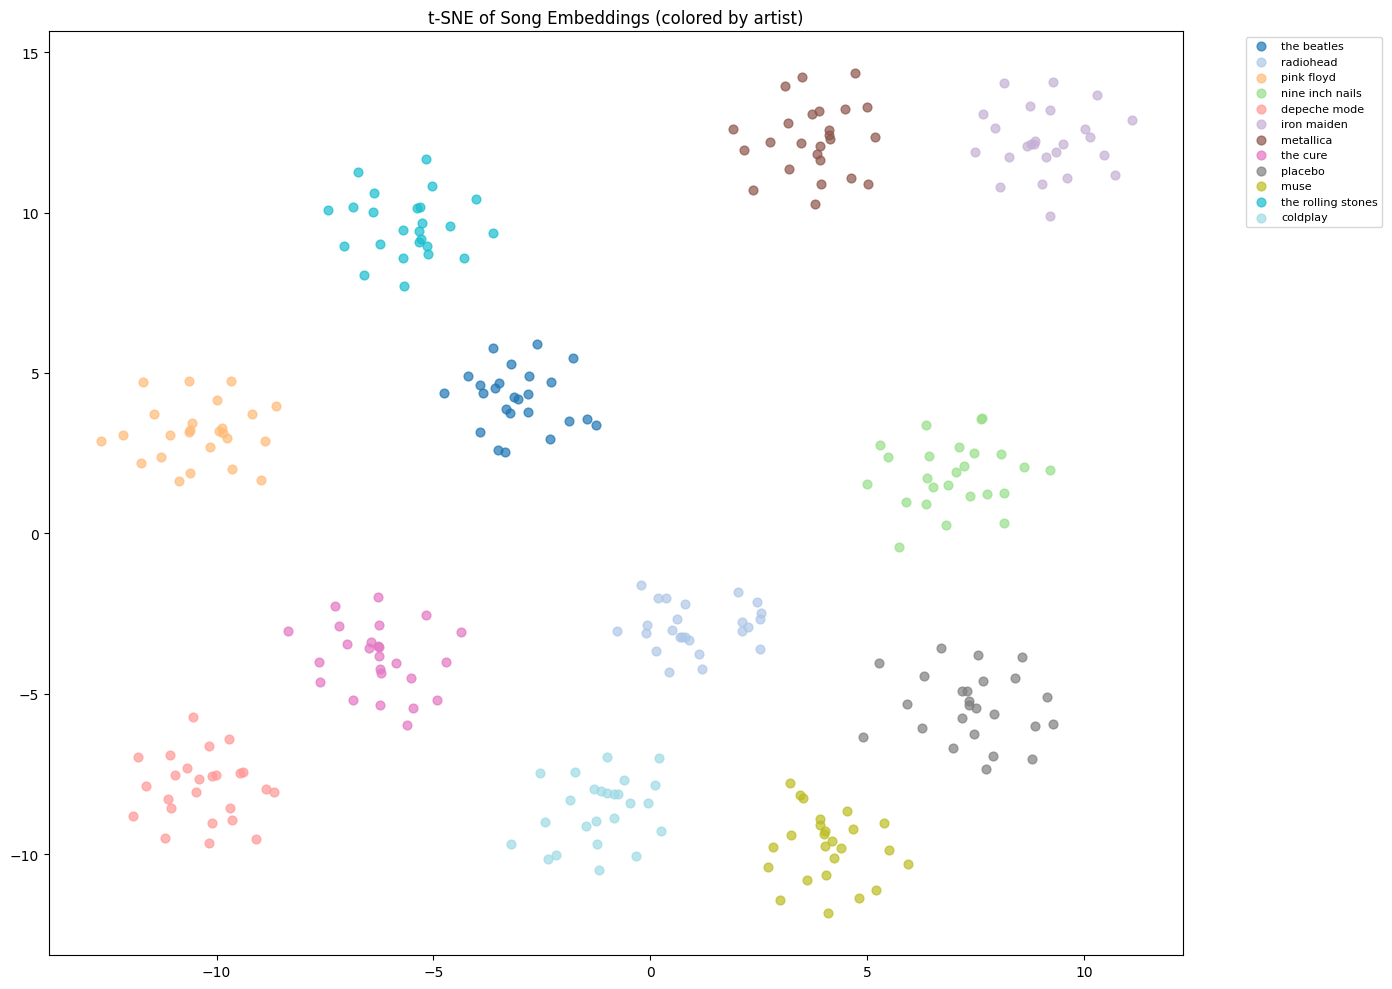

In [37]:
plt.figure(figsize=(14, 10))
colors = plt.cm.tab20(np.linspace(0, 1, N_ARTISTS))

for i, artist in enumerate(top_artists):
    mask = [a == artist for a in all_labels]
    plt.scatter(coords[mask, 0], coords[mask, 1], c=[colors[i]],
                label=artist[:25], alpha=0.7, s=40)

plt.title("t-SNE of Song Embeddings (colored by artist)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Tracks by the same artist form tight, well-separated clusters, consistent with the artist-dominated neighbour lists above.

## 4. Recommender

### Recommendation function

The seed tracks' embeddings are averaged, and the tracks closest to that mean vector are returned, excluding the seeds themselves.

In [ ]:
def recommend_songs(seed_songs, model, top_k=10):
    valid = [s for s in seed_songs if s in model.wv]
    if not valid:
        print("No seeds in vocabulary!")
        return []

    # average the seed embeddings, the same idea as averaging word vectors for a sentence
    avg_vec = np.mean([model.wv[s] for s in valid], axis=0)

    similar = model.wv.similar_by_vector(avg_vec, topn=top_k + len(valid))
    seed_set = set(valid)
    return [t for t, _ in similar if t not in seed_set][:top_k]

In [39]:
# demo
print("=== Recommendation Demo ===")
demo_seeds = seeds[:3]
print(f"Seeds: {demo_seeds}\n")

for i, r in enumerate(recommend_songs(demo_seeds, optimized_model, 10), 1):
    print(f"  {i:2d}. {r}")

=== Recommendation Demo ===
Seeds: ['queen__bohemian rhapsody', 'led zeppelin__stairway to heaven', 'nirvana__smells like teen spirit']

   1. queen__we will rock you
   2. led zeppelin__whole lotta love
   3. queen__another one bites the dust
   4. nirvana__rape me
   5. nirvana__come as you are
   6. guns n' roses__sweet child o' mine
   7. queen__don't stop me now
   8. deep purple__smoke on the water
   9. jimi hendrix__hey joe
  10. nirvana__lithium


Combining seeds from different artists produces more diverse output than single-seed queries: besides Queen, Led Zeppelin and Nirvana tracks, the list includes Guns N' Roses, Deep Purple and Jimi Hendrix.

### Cold-start analysis

In [40]:
model_vocab = set(optimized_model.wv.key_to_index.keys())
all_unique = set(t for pl in playlists for t in pl)
test_unique = set(t for pl in test_playlists for t in pl)

excluded = all_unique - model_vocab
test_oov = test_unique - model_vocab

print("=== Cold-Start Analysis ===")
print(f"Unique tracks in data:  {len(all_unique):,}")
print(f"In model vocabulary:    {len(model_vocab):,}")
print(f"Excluded by min_count:  {len(excluded):,} ({100*len(excluded)/len(all_unique):.1f}%)")
print(f"\nTest set unique tracks: {len(test_unique):,}")
print(f"Test OOV:               {len(test_oov):,} ({100*len(test_oov)/len(test_unique):.1f}%)")

=== Cold-Start Analysis ===
Unique tracks in data:  444,075
In model vocabulary:    21,393
Excluded by min_count:  422,682 (95.2%)

Test set unique tracks: 162,431
Test OOV:               142,195 (87.5%)


Cold start is severe: with `min_count=10`, only 21,393 of 444,075 unique tracks (4.8%) are in the vocabulary, and 142,195 of 162,431 unique test tracks (87.5%) are out of vocabulary.

### Artist fallback coverage

An out-of-vocabulary track can be approximated by the mean embedding of the same artist's in-vocabulary tracks. The cell below measures how many out-of-vocabulary test tracks this fallback could cover.

In [41]:
# for OOV tracks, use average embedding of known tracks by same artist
artist_to_known = defaultdict(list)
for t in model_vocab:
    artist_to_known[t.split("__")[0]].append(t)

recoverable = sum(1 for t in test_oov if t.split("__")[0] in artist_to_known)
print(f"\nOOV recoverable via artist fallback: {recoverable}/{len(test_oov)} "
      f"({100*recoverable/max(1,len(test_oov)):.1f}%)")


OOV recoverable via artist fallback: 71088/142195 (50.0%)


The fallback covers 71,088 of 142,195 out-of-vocabulary test tracks (50.0%). The rest belong to artists with no track above the frequency threshold, so there is nothing to fall back on.

### HR@10 by target popularity

Single-query HR@10 on the first 2,000 test playlists, grouped by how often the target track appears in the training playlists.

In [42]:
train_counts = Counter(t for pl in train_playlists for t in pl)

for label, lo, hi in [("Rare (<10)", 0, 9), ("Medium (10-100)", 10, 100), ("Frequent (>100)", 101, 9999999)]:
    hits, n = 0, 0
    for pl in test_playlists[:2000]:
        inv = [s for s in pl if s in model_vocab]
        if len(inv) < 2:
            continue
        target, query = inv[-1], inv[-2]
        freq = train_counts.get(target, 0)
        if freq < lo or freq > hi:
            continue
        preds = [s for s, _ in optimized_model.wv.most_similar(query, topn=11) if s != query][:10]
        n += 1
        if target in preds:
            hits += 1
    hr = hits/n if n > 0 else 0
    print(f"  {label:20s}  HR@10 = {hr:.4f}  (n={n})")

  Rare (<10)            HR@10 = 0.0000  (n=0)
  Medium (10-100)       HR@10 = 0.1014  (n=1262)
  Frequent (>100)       HR@10 = 0.0714  (n=266)


No rare targets (fewer than 10 training occurrences) can be evaluated, because they all fall below `min_count=10`. Counterintuitively, medium-frequency targets (10–100) reach a higher HR@10 (0.1014, n=1,262) than frequent ones (over 100; 0.0714, n=266). Very popular tracks appear in so many different playlist contexts that their embeddings become too generic to predict accurately, and the ZZ Top outlier likely contributes as well.

## 5. Summary

In [43]:
print("=" * 50)
print("SUMMARY")
print("=" * 50)
print(f"\nBaseline:  HR@10 = {base_res['paper']['HR'][10]:.4f}")
print(f"Optimized: HR@10 = {opt_res['paper']['HR'][10]:.4f}")
if base_res['paper']['HR'][10] > 0:
    imp = (opt_res['paper']['HR'][10] / base_res['paper']['HR'][10] - 1) * 100
    print(f"Improvement: {imp:+.1f}%")
print(f"\nBest params: ns_exp={best_ns}, window={best_win}, "
      f"epochs={best_ep}, sg={best_sg}, neg={best_neg}, "
      f"min_count={best_mc}, vec_size={best_vs}")

SUMMARY

Baseline:  HR@10 = 0.0145
Optimized: HR@10 = 0.0930
Improvement: +541.4%

Best params: ns_exp=0, window=10, epochs=50, sg=1, neg=15, min_count=10, vec_size=100


## Discussion & Results

**Hyperparameters matter.** Moving from NLP defaults to a configuration tuned for recommendation raised single-query HR@10 from 0.0145 to 0.0930 (+541.4%). Training epochs and `min_count` drove most of the gain. `ns_exponent`, the key parameter in Caselles-Dupré et al. (2018), made little difference on this data, likely because of the extreme ZZ Top outlier (31,036 occurrences).

**Coverage vs. quality.** With `min_count=5` the vocabulary holds 54,623 tracks; with `min_count=10` it shrinks to 21,393. Lowering the threshold to 3 drops HR@10 to 0.0146 because the model spends capacity on noisy tracks, while `min_count=10` gives the best HR@10 (0.0537) but excludes 95.2% of unique tracks and leaves 87.5% of unique test tracks out of vocabulary.

**Failure analysis**

| Input / query | Model output | Expected output | Error type | Likely cause |
|---|---|---|---|---|
| `queen__bohemian rhapsody` | All 10 results are Queen | Queen plus related classic rock (AC/DC, Guns N' Roses) | Artist over-representation | High intra-artist co-occurrence drowns out the cross-artist signal |
| `led zeppelin__stairway to heaven` | 8 Led Zeppelin, 2 Pink Floyd | A more varied classic rock mix | Artist over-representation | Led Zeppelin tracks co-occur frequently in fan playlists |
| `nirvana__smells like teen spirit` | All 10 results are Nirvana | Grunge mix (Pearl Jam, Soundgarden, Alice in Chains) | Artist over-representation | Very high intra-artist cosine similarity (0.63–0.83) |
| Song algebra: ZZ Top − ZZ Top + Massive Attack | Input track (`teardrop`) ranked first | Another Massive Attack or trip-hop track | Incomplete cancellation | Vector arithmetic does not cancel cleanly; the ZZ Top outlier distorts the space |
| Song algebra: Joy Division − Joy Division + Radiohead | Input track (`karma police`) ranked first | A different Radiohead track | Incomplete cancellation | Residual from imperfect subtraction |
| Any track with fewer than 10 occurrences | No recommendations possible | Should still be recommendable | Cold start | `min_count=10` excludes 95.2% of tracks |
| Frequent targets (>100 occurrences) | HR@10 = 0.0714, below medium-frequency targets | Highest accuracy | Generic embeddings | Popular tracks appear in many diverse contexts |
| Context average over short playlists (2–3 tracks) | Noisy, generic recommendations | Targeted recommendations | Information scarcity | Averaging one or two vectors is unreliable |

**Proposed fixes**
- **Artist over-representation:** multi-seed queries already diversify the output; the three-artist demo adds Guns N' Roses, Deep Purple and Jimi Hendrix. For single-seed queries, a post-processing step that caps each artist at 2–3 tracks and backfills with the next most similar tracks from other artists would improve diversity without retraining.
- **Cold start:** an artist-level fallback, which represents an unseen track by the mean embedding of its artist's known tracks, would cover 50.0% of out-of-vocabulary test tracks. For example, an unseen Radiohead track can be approximated from all known Radiohead embeddings.

**Reproducibility.** Seed 42 is used for the train/test split and every Word2Vec model. Training uses 4 worker threads, so scores vary slightly between runs even with a fixed seed. Developed on Google Colab with Python 3.12 and Gensim 4.4.0.